# Model testing with photon count matrices

In [1]:
from utils.io_npy import *
from utils.io_npz import *
from utils.error_functions import *
from utils.plotting import *
from utils.heatmaps import *
from utils.grids import *
from utils.metrics import *


import numpy as np

In [2]:
# some global parameters

NBINS = 24
BIN_FILTER = 10.0


To see how we divide an image to radial bins.

In [3]:
# plot_radial_bins(n_annuli=24,font_size=14)

In [4]:
npy_dir = "./npy_data/"
npz_dir = "./npz_data/"
used_dataset = "" #  dataset for testing

sampling_type = "DDPM" # can be DDPM or DDIM, check if samples exist for the type

REFLEX_PATH = f"{npy_dir}RefleX_Dataset_8_Testing/" #  dataset for testing
REFLEX_NPZ = f"{npz_dir}REFLEX.npz"

MODEL_A_NPZ = f"{npz_dir}MODEL_A.npz"
MODEL_B_NPZ = f"{npz_dir}MODEL_B.npz"
MODEL_C_NPZ = f"{npz_dir}MODEL_C.npz"

exclude_nH = [] # List of nH values we will exclude.
if used_dataset == "3_extended":
    exclude_nH = [1e8, 1e9, 1e10, 1e11, 1e12, 1e13, 1e14, 1e15, 
                  1e16, 1e17, 1e18, 1e19, 3.46e17, 4.64e19, 4.64e23, 1e24]

exclude_x = [] # List of x values we will exclude.
if used_dataset == "3_extended":
    exclude_x = []


save_npy_to_npz(REFLEX_PATH, out_path=REFLEX_NPZ, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x ,k = 1.0, resize_to_48=False)


Saved 225 matrices to ./npz_data/REFLEX.npz with shape (48, 48) + dmin/dmax arrays.


Saving the samples from each checkpoint from each model to an npz file

In [5]:
checkpoint_list = ["02","03","04","05","06","07","08","09","10","11","12"]

Model_A_Mean_Errors = [] 
Model_A_Error_Stds = [] 

Model_C_Mean_Errors = [] 
Model_C_Error_Stds = [] 

Model_B_Mean_Errors = []
Model_B_Error_Stds = [] 

FANO_MODEL = 0
for cpnt in checkpoint_list:

    MODEL_C_NAME = f"357_DDPM_Aux_12k_{cpnt}k_DDPM"# ANSCOMBE NOISE MSE + LABEL MSE + chi2 aux 
    MODEL_C_PATH = f"{npy_dir}{MODEL_C_NAME}"
    save_npy_to_npz(MODEL_C_PATH, out_path=MODEL_C_NPZ, checkpoint=cpnt, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x,k = 1.0)

    # MODEL C 
    Model_C_Mean_Error, Model_C_Error_Std = mean_error_between_npz(
        npz_model_path=f"{npz_dir}MODEL_C_{cpnt}k.npz",
        npz_data_path=REFLEX_NPZ,
        error_func = radial_reduced_chi2_area2_bin_filtered,
        err_kwargs=dict(bin_filter=10, n_annuli=24, Fano_Data=1, Fano_Model=1),
    )

    Model_C_Mean_Errors.append(Model_C_Mean_Error)
    Model_C_Error_Stds.append(Model_C_Error_Std)

    MODEL_A_NAME = f"359_DDPM_Non_Anscombe_12k_{cpnt}k_{sampling_type}"
    MODEL_A_PATH = f"{npy_dir}{MODEL_A_NAME}"
    save_npy_to_npz(MODEL_A_PATH, out_path=MODEL_A_NPZ, checkpoint=cpnt, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x,k = 1.0)

    Model_A_Mean_Error, Model_A_Error_Std = mean_error_between_npz(
        npz_model_path=f"{npz_dir}MODEL_A_{cpnt}k.npz",
        npz_data_path=REFLEX_NPZ,
        error_func = radial_reduced_chi2_area2_bin_filtered,
        err_kwargs=dict(bin_filter=10, n_annuli=24, Fano_Data=1, Fano_Model=1),
    )

    Model_A_Mean_Errors.append(Model_A_Mean_Error)
    Model_A_Error_Stds.append(Model_A_Error_Std)

    # MODEL B
    MODEL_B_NAME = f"358_DDPM_Anscombe_12k_{cpnt}k_{sampling_type}" # ANSCOMBE NOISE MSE + LABEL MSE
    MODEL_B_PATH = f"{npy_dir}{MODEL_B_NAME}"
    save_npy_to_npz(MODEL_B_PATH, out_path=MODEL_B_NPZ, checkpoint=cpnt, pattern="*.npy", exclude_nH=exclude_nH, exclude_x = exclude_x,k = 1.0)

    Model_B_Mean_Error, Model_B_Error_Std = mean_error_between_npz(
        npz_model_path=f"{npz_dir}MODEL_B_{cpnt}k.npz",
        npz_data_path=REFLEX_NPZ,
        error_func = radial_reduced_chi2_area2_bin_filtered,
        err_kwargs=dict(bin_filter=10, n_annuli=24, Fano_Data=1, Fano_Model=1),
    )

    Model_B_Mean_Errors.append(Model_B_Mean_Error)
    Model_B_Error_Stds.append(Model_B_Error_Std)


Saved 225 matrices to ./npz_data/MODEL_C_02k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_A_02k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_B_02k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_C_03k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_A_03k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_B_03k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_C_04k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_A_04k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_B_04k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_C_05k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to ./npz_data/MODEL_A_05k.npz with shape (48, 48) + dmin/dmax arrays.
Saved 225 matrices to

In [6]:
seed_list = [45, 107, 115, 284, 334]  # replace with your seeds

for seed in seed_list:
    custom_npy_pth = (
        f"{npy_dir}"
        f"RefleX_Different_Seed_Grid_Increased_Camera_Center_Distance/"
        f"seed_{seed}/npy"
    )

    save_npy_to_npz(
        custom_npy_pth,
        out_path=f"{npz_dir}seed_{seed}.npz",
        checkpoint="00",
        pattern="*.npy",
        exclude_nH=[1e24],
        exclude_x=exclude_x,
        k=1.0,
    )

Saved 12 matrices to ./npz_data/seed_45_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data/seed_107_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data/seed_115_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data/seed_284_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).
Saved 12 matrices to ./npz_data/seed_334_00k.npz with shape (50, 50) + dmin/dmax arrays. Skipped 4 due to exclude_nH=[1e+24] (tol=0.0).


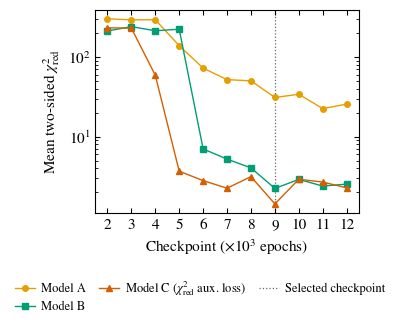

In [7]:
import numpy as np
import matplotlib.pyplot as plt

JOURNAL_RC = {
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.size": 2.0,
    "ytick.minor.size": 2.0,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "axes.linewidth": 0.8,
    "legend.frameon": False,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
}

x = np.array([int(c) for c in checkpoint_list])

with plt.rc_context(JOURNAL_RC):
    fig, ax = plt.subplots(figsize=(3.5, 2.8))

    ax.plot(
        x, Model_A_Mean_Errors,
        marker="o", markersize=4, linewidth=1.0,
        color="#E69F00", label="Model A",
    )
    ax.plot(
        x, Model_B_Mean_Errors,
        marker="s", markersize=4, linewidth=1.0,
        color="#009E73", label="Model B",
    )
    ax.plot(
        x, Model_C_Mean_Errors,
        marker="^", markersize=4, linewidth=1.0,
        color="#D55E00",
        label=r"Model C ($\chi^2_{\mathrm{red}}$ aux. loss)",
    )



    ax.set_xlabel(r"Checkpoint ($\times 10^{3}$ epochs)")
    ax.set_ylabel(r"Mean two-sided $\chi^2_{\mathrm{red}}$")
    ax.set_yscale("log")
    ax.set_xticks(x)
    picked = 9  # checkpoint in 10^3 epochs
    ax.axvline(
        x=picked,
        color="0.4",
        linestyle=":",
        linewidth=0.9,
        label="Selected checkpoint",
        zorder=1,
    )
    fig.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 0.02),
        ncol=3,
        fontsize=9,
        handlelength=1.6,
        columnspacing=1.0,
        handletextpad=0.5,
    )

    plt.tight_layout()
    plt.show()

In [8]:
custom_npy_pth = f"{npy_dir}Single_Vs_All_Scat_July_10_Data/data/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}all_scat.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 40 matrices to ./npz_data/all_scat.npz with shape (48, 48) + dmin/dmax arrays.


In [9]:
custom_npy_pth = f"{npy_dir}Single_Vs_All_Scat_July_10_Data/singlescat_data/npy/"

save_npy_to_npz(f"{custom_npy_pth}", 
                out_path=f"{npz_dir}single_scat.npz", 
                checkpoint="",
                pattern="*.npy", 
                exclude_nH=exclude_nH, 
                exclude_x = exclude_x,k = 1.0)

Saved 40 matrices to ./npz_data/single_scat.npz with shape (48, 48) + dmin/dmax arrays.


 Summary: error grid
 Grid                : 10 x 4  (40 cells, 40 finite, 0 missing)
 Mean                : 2.1883
 Std (ddof=1)        : 1.5337     SEM: 0.2425
 Median              : 2.0768
 Trimmed mean (10%)  : 2.1037
 Geometric mean      : 1.3692
 IQR                 : 1.0036 - 3.3165
 Percentiles         : p90=4.2527  p95=4.8915  p99=5.3627
 Min / Max           : 0.0162 / 5.5782
 Fraction <= 1.00    :  25.00%  (10/40)
 Fraction <= 2.00    :  47.50%  (19/40)
 Fraction <= 3.00    :  72.50%  (29/40)
------------------------------------------------------------------
 Extremes
   Lowest       0.0162  at x=0.9700, nH=1.000e+21
   Highest      5.5782  at x=0.0500, nH=3.530e+22
   ~Mean        2.2044  at x=0.3467, nH=2.260e+22
   ~Median      2.0033  at x=0.9700, nH=8.620e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 6/40 cells (15.0%)
     x=0.0500  nH=3.530e+22   value=5.58
     x=0.0500 

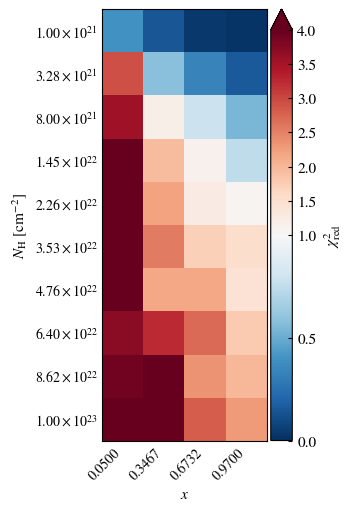

In [10]:
Error_Heatmap_C, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}single_scat.npz",
    npz_data_path=f"{npz_dir}all_scat.npz",
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    cmap="magma",
    diverging = True,
    vmin=0.0,
    vmax=4.0,
    figsize=(3.53, 5.25)
)

x=3467.0 -> matched x=3467.0
nH=2.26e+22 -> matched nH=2.26e+22

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Dust Scattering = 1 vs Dust Scattering > 0
    chi2_red (Dust Scattering = 1 as data) = 2.3791   N_best=0.8426
    chi2_red (Dust Scattering > 0 as data) = 2.2044   N_best=1.1934
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Dust Scattering = 1) | counts(Dust Scattering > 0) | Dust Scattering = 1->Dust Scattering > 0 | Dust Scattering > 0->Dust Scattering = 1
        1 |        31.157 |      8100.000 |      638.000 |       670.000 |  6.9250e-01 |  5.8771e-01
        2 |        93.471 |     40500.000 |      688.000 |       804.000 |  1.2677e-02 |  1.8101e-02
        3 |       155.784 |     56700.000 |      216.000 |       266.000 |  2.3296e-02 |  1.3118e-02
        4 |       218.098 |     89100.000 |      102

/Users/atakansarac/Desktop/WorkStation/astro/paper/code_and_data/analysis/utils/error_functions.py:1029: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


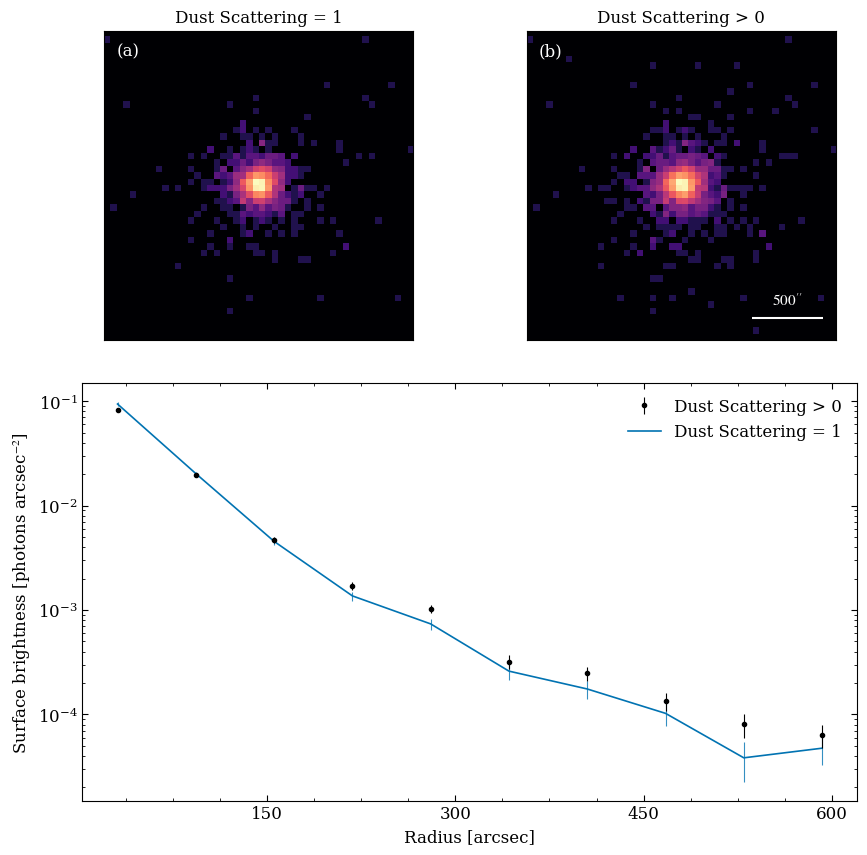

In [11]:


results = compare_npz_by_params(
    3467.0, 2.26e22,
    npz_paths=[
               f"{npz_dir}single_scat.npz",
               f"{npz_dir}all_scat.npz",
               ],  # last = data
    labels=["Dust Scattering = 1","Dust Scattering > 0"],
    cmaps=["magma", "magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)


 Summary: error grid
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Mean                : 1.4304
 Std (ddof=1)        : 4.7268     SEM: 0.3151
 Median              : 0.6528
 Trimmed mean (10%)  : 0.7552
 Geometric mean      : 0.7375
 IQR                 : 0.4727 - 1.0019
 Percentiles         : p90=1.7616  p95=2.3934  p99=18.1525
 Min / Max           : 0.1038 / 62.2435
 Fraction <= 1.00    :  74.22%  (167/225)
 Fraction <= 2.00    :  92.00%  (207/225)
 Fraction <= 3.00    :  95.11%  (214/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.1038  at x=0.6287, nH=9.280e+22
   Highest     62.2435  at x=0.0648, nH=1.950e+21
   ~Mean        1.4209  at x=0.7770, nH=9.280e+22
   ~Median      0.6528  at x=0.8958, nH=1.080e+21
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 7/225 cells (3.1%)
     x=0.0648  nH=1.950e+21   value=62.24
  

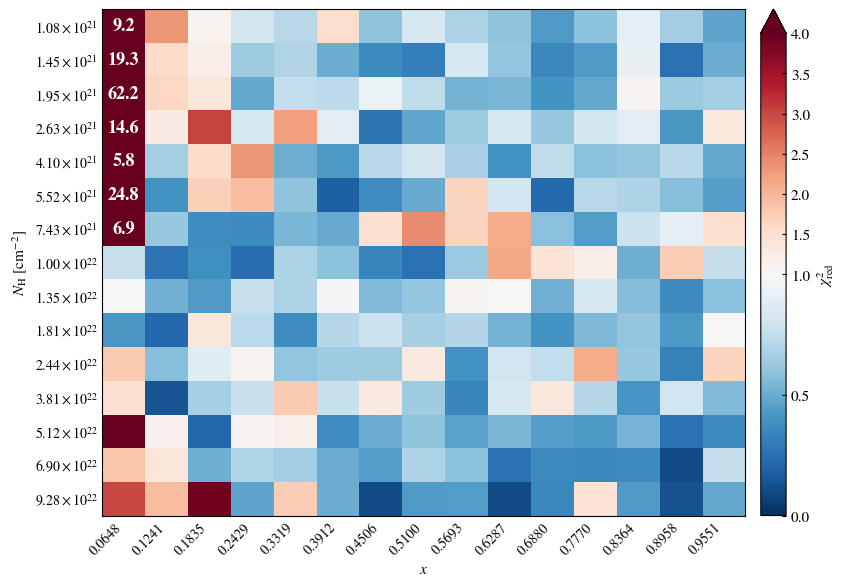

In [12]:
Error_Heatmap_B, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_C_09k.npz",
    npz_data_path=REFLEX_NPZ,
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    diverging = True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

 Summary: error grid
 Grid                : 15 x 15  (225 cells, 225 finite, 0 missing)
 Mean                : 2.2412
 Std (ddof=1)        : 8.4640     SEM: 0.5643
 Median              : 0.8110
 Trimmed mean (10%)  : 1.0301
 Geometric mean      : 0.9370
 IQR                 : 0.5071 - 1.6331
 Percentiles         : p90=2.8876  p95=5.0650  p99=35.0831
 Min / Max           : 0.1042 / 108.8900
 Fraction <= 1.00    :  59.56%  (134/225)
 Fraction <= 2.00    :  82.22%  (185/225)
 Fraction <= 3.00    :  90.22%  (203/225)
------------------------------------------------------------------
 Extremes
   Lowest       0.1042  at x=0.8958, nH=6.900e+22
   Highest    108.8900  at x=0.0648, nH=1.080e+21
   ~Mean        2.2451  at x=0.5100, nH=1.810e+22
   ~Median      0.8110  at x=0.7770, nH=6.900e+22
------------------------------------------------------------------
 Colour scale        : vmin=0, vmax=4, extend='max'
 Clipped above vmax  : 15/225 cells (6.7%)
     x=0.0648  nH=1.080e+21   value=108.89

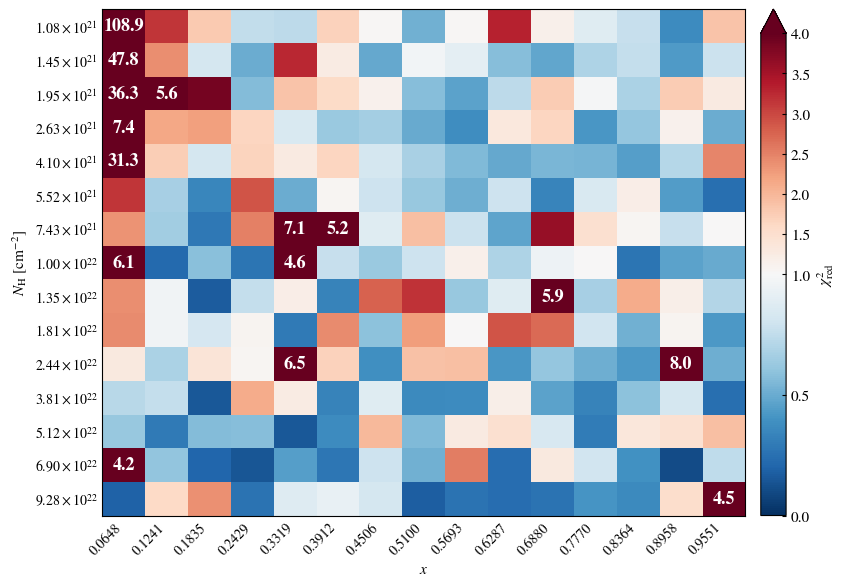

In [13]:
Error_Heatmap_B, xs, nHs = error_heatmap_between_npz(
    npz_model_path=f"{npz_dir}MODEL_B_09k.npz",
    npz_data_path=REFLEX_NPZ,
    bin_filter=10,
    n_annuli=24,
    Fano_Data=1,
    Fano_Model=1,
    diverging = True,
    cmap="magma",
    figsize=(9, 6),
    vmin=0.0,
    vmax=4.0,
    annotate_above=4,
    annotate_fontsize=13,
)

x=4506.0 -> matched x=4506.0
nH=5.12e+22 -> matched nH=5.12e+22

Pairwise chi2_red (chi2):
  n_annuli=24, bin_filter=10.0, Fano Data=1.0, Fano Model=1.0, pixel_scale=45"
-------------------------------------------------------
  Model C vs RefleX
    chi2_red (Model C as data) = 1.9914   N_best=0.9807
    chi2_red (RefleX as data) = 2.0489   N_best=1.0257
    per-annulus reduced chi2_red contributions:
      bin | radius[arcsec] | area[arcsec^2] | counts(Model C) | counts(RefleX) | Model C->RefleX | RefleX->Model C
        1 |        31.157 |      8100.000 |      384.208 |       378.000 |  4.0689e-02 |  4.7159e-02
        2 |        93.471 |     40500.000 |      460.688 |       415.000 |  5.5911e-01 |  5.2523e-01
        3 |       155.784 |     56700.000 |      160.210 |       186.000 |  2.4216e-01 |  1.8936e-01
        4 |       218.098 |     89100.000 |       88.808 |       110.000 |  3.1136e-01 |  2.5119e-01
        5 |       280.412 |    105300.000 |       52.980 |        63.000 |  

/Users/atakansarac/Desktop/WorkStation/astro/paper/code_and_data/analysis/utils/error_functions.py:1029: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


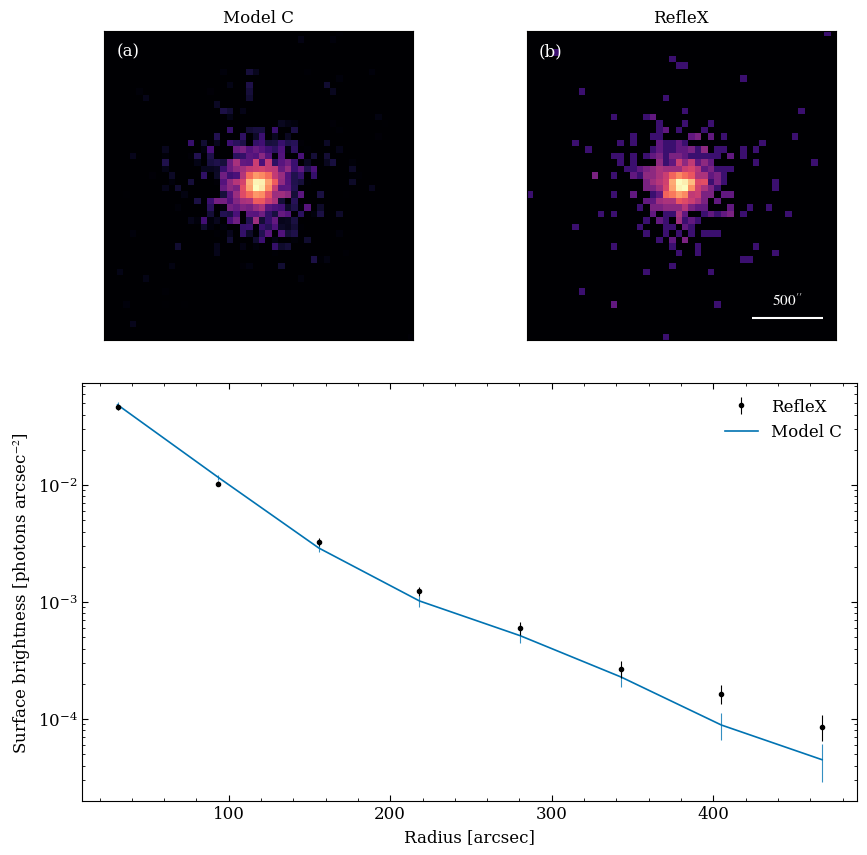

In [14]:

x = 4506.0
nH = 5.12e+22
results = compare_npz_by_params(
    x, nH,
    npz_paths=[
               "./npz_data/MODEL_C_08k.npz", 
               REFLEX_NPZ,
               ],  # last = data
    labels=["Model C", "RefleX"],
    cmaps=["magma", "magma","magma"],
    n_annuli=24, bin_filter=10.0, pixel_scale_arcsec=45,
    a=200.0, center="geom", figsize=(10,10), font_size=12,
)
